In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import sys
sys.path.append("../../../")
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
cobra.Configuration().solver = "glpk"

In [2]:
with open('../../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    clustered_nodes = pickle.load(f)

with open('../../../Coarse_graining_result/clustered_nodes_c10_s44_pq1_relabeled.pkl', 'rb') as f:
    clustered_nodes2 = pickle.load(f)

with open('../../../Coarse_graining_result/clustered_nodes_c40_s44_pq1_relabeled.pkl', 'rb') as f:
    clustered_nodes3 = pickle.load(f)

In [3]:
def invert_clusters(cluster_dict):
    return {
        node: cluster
        for cluster, nodes in cluster_dict.items()
        for node in nodes
    }

inv10 = invert_clusters(clustered_nodes2)
inv20 = invert_clusters(clustered_nodes)
inv40 = invert_clusters(clustered_nodes3)

nodes10 = set(inv10)
nodes20 = set(inv20)
nodes40 = set(inv40)

assert nodes10 == nodes20 == nodes40, \
    "K=10, K=20 and K=40 do not contain exactly the same network nodes."

all_nodes = sorted(nodes10)

labels_df = pd.DataFrame({
    "node": all_nodes,
    "K10": [inv10[node] for node in all_nodes],
    "K20": [inv20[node] for node in all_nodes],
    "K40": [inv40[node] for node in all_nodes]
})

overlap_10_20 = pd.crosstab(
    labels_df["K10"],
    labels_df["K20"]
)

overlap_20_40 = pd.crosstab(
    labels_df["K20"],
    labels_df["K40"]
)

size_k10 = labels_df["K10"].value_counts()

order_k10 = list(
    size_k10.sort_values(ascending=False).index
)

rank_k10 = {
    cluster: rank
    for rank, cluster in enumerate(order_k10)
}

parent_k20 = overlap_10_20.idxmax(axis=0).to_dict()
dominant_overlap_k20 = overlap_10_20.max(axis=0).to_dict()
size_k20 = overlap_10_20.sum(axis=0).to_dict()

order_k20 = sorted(
    overlap_10_20.columns,
    key=lambda cluster: (
        rank_k10[parent_k20[cluster]],
        -dominant_overlap_k20[cluster],
        -size_k20[cluster],
        str(cluster)
    )
)

rank_k20 = {
    cluster: rank
    for rank, cluster in enumerate(order_k20)
}

parent_k40 = overlap_20_40.idxmax(axis=0).to_dict()
dominant_overlap_k40 = overlap_20_40.max(axis=0).to_dict()
size_k40 = overlap_20_40.sum(axis=0).to_dict()

order_k40 = sorted(
    overlap_20_40.columns,
    key=lambda cluster: (
        rank_k20[parent_k40[cluster]],
        -dominant_overlap_k40[cluster],
        -size_k40[cluster],
        str(cluster)
    )
)
n_nodes = len(all_nodes)

orders = {
    10: order_k10,
    20: order_k20,
    40: order_k40
}

cluster_sizes = {
    10: labels_df["K10"].value_counts().to_dict(),
    20: labels_df["K20"].value_counts().to_dict(),
    40: labels_df["K40"].value_counts().to_dict()
}

cluster_spans = {}

for k in [10, 20, 40]:

    order = orders[k]
    gap = 0.004
    available_width = 1 - gap * (len(order) - 1)

    spans = {}
    cursor = 0

    for cluster in order:
        width = (
            cluster_sizes[k][cluster]
            / n_nodes
            * available_width
        )

        spans[cluster] = (
            cursor,
            cursor + width
        )

        cursor += width + gap

    cluster_spans[k] = spans

flow_10_20 = {}

for cluster10 in order_k10:

    cursor = cluster_spans[10][cluster10][0]

    for cluster20 in order_k20:

        value = overlap_10_20.loc[
            cluster10,
            cluster20
        ]

        if value == 0:
            continue

        width = (
            value / n_nodes
            * (
                1 - 0.004 * (len(order_k10) - 1)
            )
        )

        flow_10_20.setdefault(
            (cluster10, cluster20),
            {}
        )

        flow_10_20[(cluster10, cluster20)]["source"] = (
            cursor,
            cursor + width
        )

        cursor += width

for cluster20 in order_k20:

    cursor = cluster_spans[20][cluster20][0]

    for cluster10 in order_k10:

        value = overlap_10_20.loc[
            cluster10,
            cluster20
        ]

        if value == 0:
            continue

        width = (
            value / n_nodes
            * (
                1 - 0.004 * (len(order_k20) - 1)
            )
        )

        flow_10_20[(cluster10, cluster20)]["target"] = (
            cursor,
            cursor + width
        )

        cursor += width


flow_20_40 = {}

for cluster20 in order_k20:

    cursor = cluster_spans[20][cluster20][0]

    for cluster40 in order_k40:

        value = overlap_20_40.loc[
            cluster20,
            cluster40
        ]

        if value == 0:
            continue

        width = (
            value / n_nodes
            * (
                1 - 0.004 * (len(order_k20) - 1)
            )
        )

        flow_20_40.setdefault(
            (cluster20, cluster40),
            {}
        )

        flow_20_40[(cluster20, cluster40)]["source"] = (
            cursor,
            cursor + width
        )

        cursor += width

for cluster40 in order_k40:

    cursor = cluster_spans[40][cluster40][0]

    for cluster20 in order_k20:

        value = overlap_20_40.loc[
            cluster20,
            cluster40
        ]

        if value == 0:
            continue

        width = (
            value / n_nodes
            * (
                1 - 0.004 * (len(order_k40) - 1)
            )
        )

        flow_20_40[(cluster20, cluster40)]["target"] = (
            cursor,
            cursor + width
        )

        cursor += width

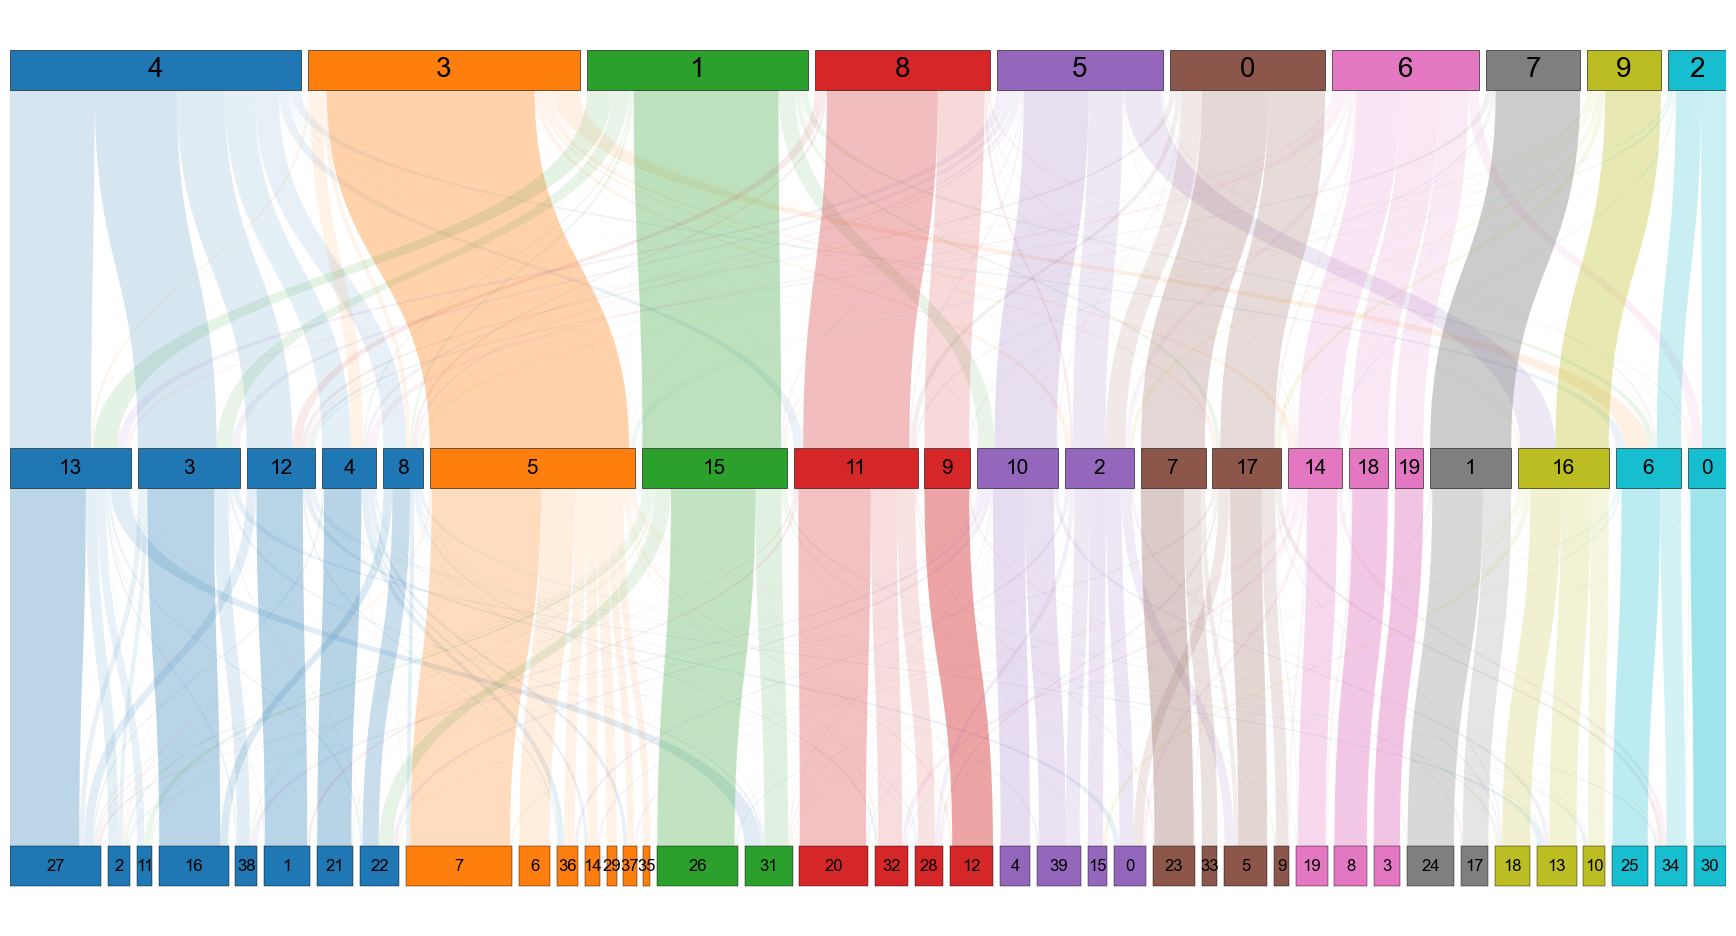

In [4]:
from matplotlib.path import Path
from matplotlib.patches import PathPatch, Rectangle

set_panel_style(scale=4)
cmap = plt.get_cmap("tab10")

color_k10 = {
    cluster: cmap(i)
    for i, cluster in enumerate(order_k10)
}

root_k20 = {
    cluster20: parent_k20[cluster20]
    for cluster20 in order_k20
}

root_k40 = {
    cluster40: parent_k20[parent_k40[cluster40]]
    for cluster40 in order_k40
}

fig, ax = plt.subplots(figsize=(18, 10))

y_position = {
    10: 2.0,
    20: 1.0,
    40: 0.0
}

node_height = 0.10

for (cluster10, cluster20), positions in flow_10_20.items():

    sx0, sx1 = positions["source"]
    tx0, tx1 = positions["target"]

    source_y = y_position[10] - node_height / 2
    target_y = y_position[20] + node_height / 2
    middle_y = (source_y + target_y) / 2

    vertices = [
        (sx0, source_y),

        (sx0, middle_y),
        (tx0, middle_y),
        (tx0, target_y),

        (tx1, target_y),

        (tx1, middle_y),
        (sx1, middle_y),
        (sx1, source_y),

        (sx0, source_y)
    ]

    codes = [
        Path.MOVETO,

        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,

        Path.LINETO,

        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,

        Path.CLOSEPOLY
    ]

    path = Path(vertices, codes)

    value = overlap_10_20.loc[cluster10, cluster20]
    source_size = cluster_sizes[10][cluster10]
    flow_fraction = value / source_size

    alpha = 0.08 + 0.35 * flow_fraction

    patch = PathPatch(
        path,
        facecolor=color_k10[cluster10],
        edgecolor="none",
        alpha=alpha
    )

    ax.add_patch(patch)

for (cluster20, cluster40), positions in flow_20_40.items():

    sx0, sx1 = positions["source"]
    tx0, tx1 = positions["target"]

    source_y = y_position[20] - node_height / 2
    target_y = y_position[40] + node_height / 2
    middle_y = (source_y + target_y) / 2

    vertices = [
        (sx0, source_y),

        (sx0, middle_y),
        (tx0, middle_y),
        (tx0, target_y),

        (tx1, target_y),

        (tx1, middle_y),
        (sx1, middle_y),
        (sx1, source_y),

        (sx0, source_y)
    ]

    codes = [
        Path.MOVETO,

        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,

        Path.LINETO,

        Path.CURVE4,
        Path.CURVE4,
        Path.CURVE4,

        Path.CLOSEPOLY
    ]

    path = Path(vertices, codes)

    value = overlap_20_40.loc[cluster20, cluster40]
    source_size = cluster_sizes[20][cluster20]
    flow_fraction = value / source_size

    alpha = 0.08 + 0.35 * flow_fraction

    patch = PathPatch(
        path,
        facecolor=color_k10[root_k20[cluster20]],
        edgecolor="none",
        alpha=alpha
    )

    ax.add_patch(patch)

for cluster in order_k10:

    x0, x1 = cluster_spans[10][cluster]

    ax.add_patch(
        Rectangle(
            (x0, y_position[10] - node_height / 2),
            x1 - x0,
            node_height,
            facecolor=color_k10[cluster],
            edgecolor="black",
            linewidth=0.4
        )
    )

    ax.text(
        (x0 + x1) / 2,
        y_position[10],
        str(cluster),
        ha="center",
        va="center",
        fontsize=20
    )

for cluster in order_k20:

    x0, x1 = cluster_spans[20][cluster]

    ax.add_patch(
        Rectangle(
            (x0, y_position[20] - node_height / 2),
            x1 - x0,
            node_height,
            facecolor=color_k10[root_k20[cluster]],
            edgecolor="black",
            linewidth=0.4
        )
    )

    ax.text(
        (x0 + x1) / 2,
        y_position[20],
        str(cluster),
        ha="center",
        va="center",
        fontsize=15
    )

for cluster in order_k40:

    x0, x1 = cluster_spans[40][cluster]

    ax.add_patch(
        Rectangle(
            (x0, y_position[40] - node_height / 2),
            x1 - x0,
            node_height,
            facecolor=color_k10[root_k40[cluster]],
            edgecolor="black",
            linewidth=0.3
        )
    )

    ax.text(
        (x0 + x1) / 2,
        y_position[40],
        str(cluster),
        ha="center",
        va="center",
        fontsize=12
    )
ax.set_xlim(0, 1)
ax.set_ylim(-0.15, 2.15)

ax.set_xticks([])
ax.set_yticks([])
ax.spines[:].set_visible(False)

plt.tight_layout()
plt.show()